# Görüntü Filtreleme: Sunumla Birlikte Öğrenelim

**Temel düzey · Konu anlatımı ve uygulama**

Önce `Goruntu_Filtreleme_Gorselli_Sunum.pptx` sunumunu inceleyin; ardından bu defteri yukarıdan aşağıya çalıştırın. Her bölümde sunumdaki **büyük örnek görseli**, kısa bir açıklama, çalışan kod ve küçük bir deneme bulunur.

Bu defter, sunumdaki 9 örnekle aynı sıra ve temel parametreleri kullanır: **çekirdek → sınır yönetimi → ortalama/Gauss → sigma → medyan → filtre seçimi → bilateral → keskinleştirme → plaka**. Görsellerde bazı bölgeler daha iyi görülmesi için yakınlaştırılmış veya kırpılmıştır.

**Hedefimiz:** Kodları ezberlemek değil, filtrenin görüntüyü nasıl değiştirdiğini görerek açıklayabilmek.

## 0. Başlamadan önce

1. ZIP dosyasının **tamamını** çıkarın. Defter ve `dosyalar` klasörü aynı klasörde kalmalıdır.
2. JupyterLab, Jupyter Notebook veya VS Code ile defteri açın. Paketler eksikse terminalde `pip install -r requirements.txt` çalıştırın. Jupyter kurulu değilse ayrıca `pip install jupyterlab` çalıştırın.
3. Colab kullanıyorsanız ZIP'i yükleyip çıkarın ve çalışma dizinini defterin bulunduğu klasöre ayarlayın. Örneğin `/content` altına çıkarıldıysa `%cd /content/Goruntu_Filtreleme_Sunumla_Uyumlu` yazılabilir; gerçek yolu kontrol edin.
4. Hücreleri sırayla **Shift + Enter** ile çalıştırın. Önceden görünen çıktıları tekrar üretmek için ilgili kod hücresini yeniden çalıştırabilirsiniz.

Görseller yerel dosyalardan açılır; deneylerin kendisi internet gerektirmez. Paket kurulumu internet gerektirebilir.

In [1]:
# Paketler eksikse yorum işaretini kaldırıp bir kez çalıştırın.
# %pip install numpy matplotlib opencv-python-headless pillow

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from IPython.display import display

DOSYALAR = Path("dosyalar")
CIKTILAR = Path("ciktilar")
CIKTILAR.mkdir(exist_ok=True)
if not (DOSYALAR / "renkli_ornek.png").is_file():
    raise FileNotFoundError("Görseller bulunamadı. ZIP'i çıkarın; çalışma dizinini defterin bulunduğu klasöre ayarlayın.")
print("Hazır! Çalışma klasörü:", Path.cwd())

Hazır! Çalışma klasörü: /home/user/Goruntu_Filtreleme_Sunumla_Uyumlu


### Görselleri göstermek için yardımcı araçlar

Aşağıdaki kodu bir kez çalıştırın. `goster`, sonuçları yan yana çizer. OpenCV renkli görüntüleri **BGR**, Matplotlib ise **RGB** sırasıyla kullandığı için gösterirken renk dönüşümü yapıyoruz.

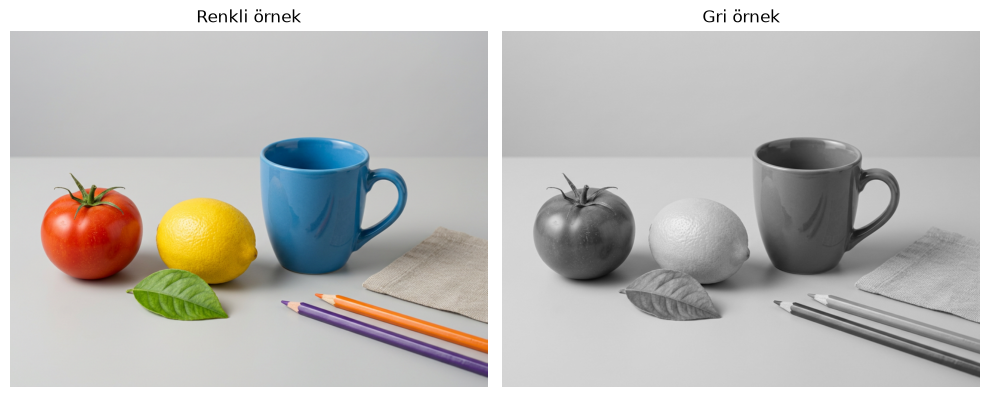

Renkli görüntünün boyutu (yükseklik, genişlik, kanal): (597, 800, 3)


In [3]:
def goster(goruntuler, basliklar):
    fig, eksenler = plt.subplots(1, len(goruntuler), figsize=(5 * len(goruntuler), 4))
    for eksen, goruntu, baslik in zip(np.atleast_1d(eksenler), goruntuler, basliklar):
        if goruntu.ndim == 2:
            eksen.imshow(goruntu, cmap="gray", vmin=0, vmax=255)
        else:
            eksen.imshow(cv2.cvtColor(goruntu, cv2.COLOR_BGR2RGB))
        eksen.set_title(baslik)
        eksen.axis("off")
    plt.tight_layout()
    plt.show()

def sunum_gorseli(dosya_adi):
    # Sunumdaki aynı örneğin küçültülmüş önizlemesi.
    yol = DOSYALAR / "ornek_gorseller" / dosya_adi
    if not yol.is_file():
        raise FileNotFoundError(f"Sunum görseli bulunamadı: {yol}")
    with Image.open(yol) as im:
        display(im.resize((960, 540)))

def yakin(goruntu):
    # Sunumda kullanılan örnek bölge: domates, limon ve bardak çevresi.
    return goruntu[180:540, 50:700]

resim = cv2.imread(str(DOSYALAR / "renkli_ornek.png"))
if resim is None:
    raise FileNotFoundError("Renkli örnek görüntü okunamadı.")
gri = cv2.cvtColor(resim, cv2.COLOR_BGR2GRAY)
goster([resim, gri], ["Renkli örnek", "Gri örnek"])
print("Renkli görüntünün boyutu (yükseklik, genişlik, kanal):", resim.shape)

**Kısaca:** Görüntü, piksel adı verilen noktalardan oluşur. Renkli görüntüde her pikselin üç kanal değeri vardır; gri görüntüde tek parlaklık değeri bulunur. 0 siyahı, 255 beyazı gösterir.

---
## 1. Çekirdek: Bir piksel nasıl hesaplanır?

**Kısa açıklama:** Çekirdek, bir pikseli ve komşularını nasıl birleştireceğimizi belirleyen küçük sayı tablosudur. 3×3 ortalama için 9 komşuluk değeri toplanır ve 9'a bölünür. Sunumdaki görselde seçilen bölgeyi ve gerçek piksel değerlerini inceleyin.

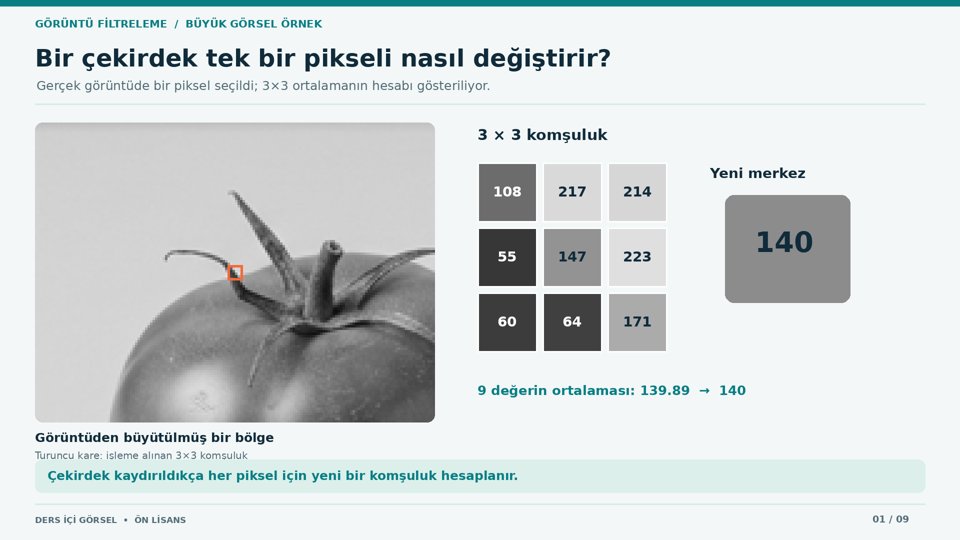

In [4]:
sunum_gorseli("01_cekirdek.png")

In [5]:
# Sunumdakiyle aynı güçlü kenar pikselini seçelim.
gx = cv2.Sobel(gri, cv2.CV_32F, 1, 0)
gy = cv2.Sobel(gri, cv2.CV_32F, 0, 1)
kenar_gucu = np.sqrt(gx * gx + gy * gy)
# Sınırın çok yakınındaki konumları seçmeyelim.
kenar_gucu[:100, :] = 0
kenar_gucu[-100:, :] = 0
kenar_gucu[:, :100] = 0
kenar_gucu[:, -100:] = 0
satir, sutun = np.unravel_index(np.argmax(kenar_gucu), kenar_gucu.shape)
komsular = gri[satir-1:satir+2, sutun-1:sutun+2]
ortalama_gri = cv2.blur(gri, (3, 3))
print("Seçilen 3×3 komşuluk:\n", komsular)
print("Elle ortalama:", round(float(komsular.mean()), 2))
print("OpenCV sonucundaki merkez piksel:", ortalama_gri[satir, sutun])

Seçilen 3×3 komşuluk:
 [[108 217 214]
 [ 55 147 223]
 [ 60  64 171]]
Elle ortalama: 139.89
OpenCV sonucundaki merkez piksel: 140


**Dene:** `komsular.mean()` yerine `np.median(komsular)` yazdırın. Ortalama ve medyan aynı olmak zorunda mı?

**Not:** `cv2.filter2D`, çekirdeği çevirmeden uygular (korelasyon). Bu derste kullandığımız simetrik çekirdeklerde matematiksel evrişimle sonuç aynıdır.

---
## 2. Sınır yönetimi: Görüntü bittiğinde ne olur?

**Kısa açıklama:** Görüntünün kenarında bazı komşular dışarıda kalır. Bunlar sıfırla doldurulabilir veya görüntü kenarı yansıtılabilir. Sınır seçimi özellikle görüntünün dış kenarlarını etkiler.

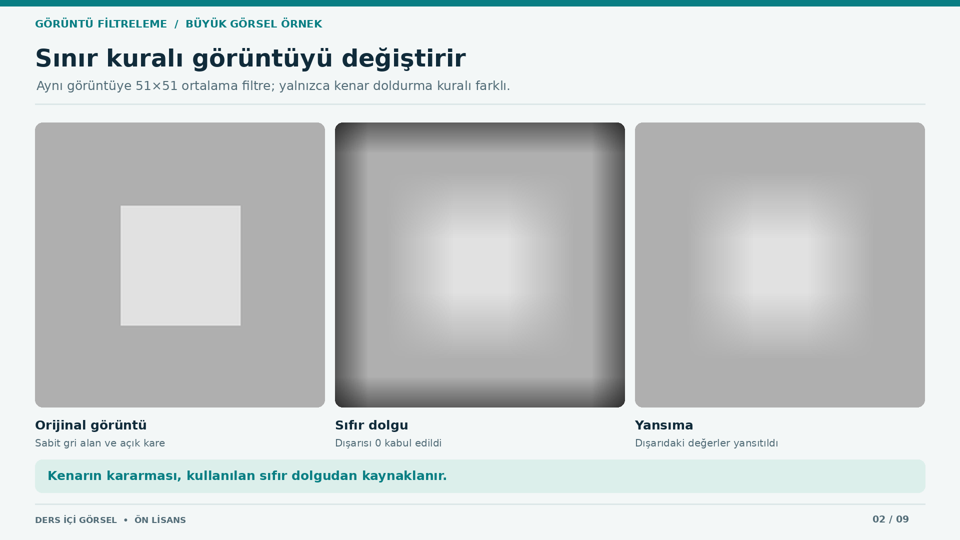

In [6]:
sunum_gorseli("02_sinir.png")

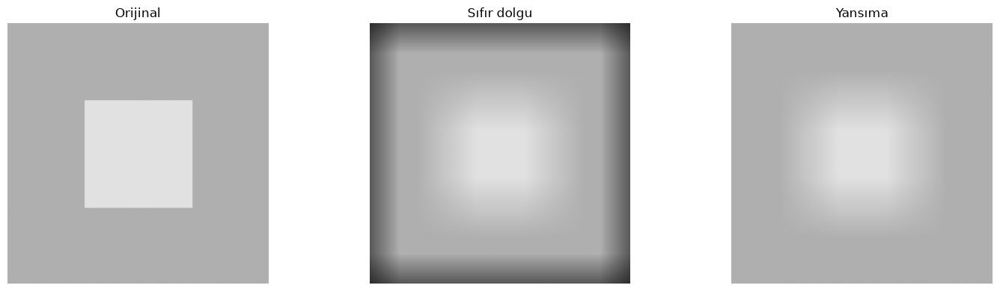

Sol üst piksel — sıfır dolgu: 45 | yansıma: 175


In [7]:
# Sunumdaki gibi gri zemin ve açık renkli bir kare oluşturalım.
sinir_ornegi = np.full((220, 220), 175, dtype=np.uint8)
sinir_ornegi[65:156, 65:156] = 225
sifir_dolgu = cv2.blur(sinir_ornegi, (51, 51), borderType=cv2.BORDER_CONSTANT)
yansima = cv2.blur(sinir_ornegi, (51, 51), borderType=cv2.BORDER_REFLECT_101)
goster([sinir_ornegi, sifir_dolgu, yansima], ["Orijinal", "Sıfır dolgu", "Yansıma"])
print("Sol üst piksel — sıfır dolgu:", sifir_dolgu[0, 0], "| yansıma:", yansima[0, 0])

**Düşünelim:** Sıfır dolguda dışarıdaki eksik komşular siyah kabul edildiğinde, kenar neden koyulaşır? OpenCV'de birçok filtre varsayılan olarak `REFLECT_101` kullanır; `medianBlur` ise kenar tekrarı kullanır.

---
## 3. Ortalama ve Gauss: Aynı fotoğrafı yumuşatalım

**Kısa açıklama:** Ortalama filtre komşulara eşit ağırlık verir. Gauss filtresi merkeze yakın piksellere daha fazla ağırlık verir. İkisi de görüntüyü yumuşatabilir. Aşağıda sunumdaki gibi **51×51** pencere kullanıyoruz; farkın belirginleşmesi için büyük bir boyut seçilmiştir.

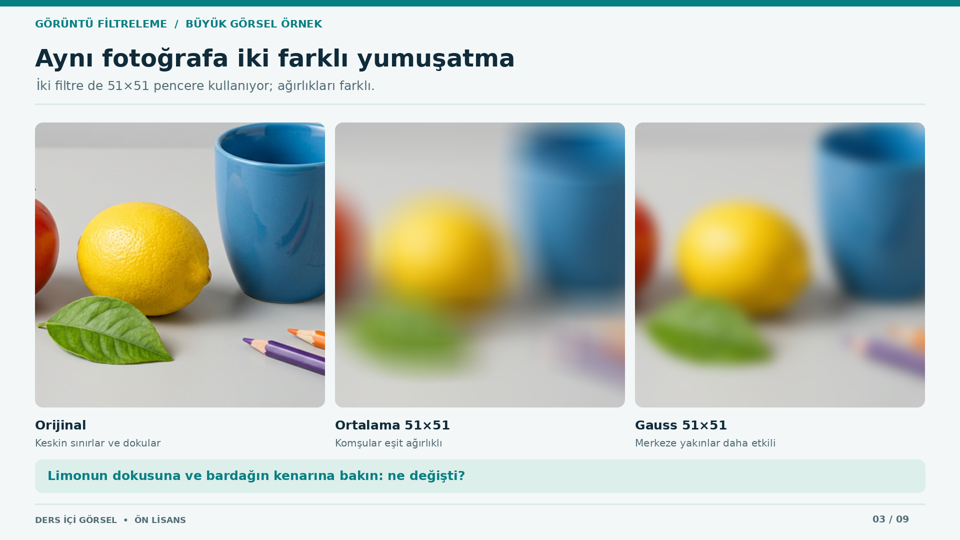

In [8]:
sunum_gorseli("03_ortalama_gauss.png")

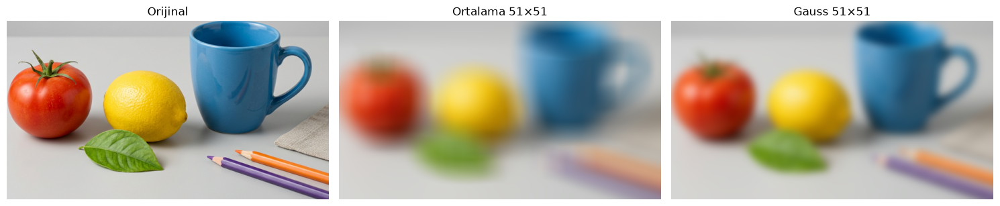

In [9]:
ortalama_51 = cv2.blur(resim, (51, 51))
gauss_51 = cv2.GaussianBlur(resim, (51, 51), 0)  # 0: sigma otomatik
# Sunumdaki gibi fotoğrafın aynı bölgesini inceleyelim.
goster([yakin(resim), yakin(ortalama_51), yakin(gauss_51)],
       ["Orijinal", "Ortalama 51×51", "Gauss 51×51"])

**Dene:** İki filtrede de `51` yerine `11` yazın. Limonun dokusu ve bardağın kenarı daha mı belirgin kaldı?

---
## 4. Gauss'ta sigma: Yayılma ne kadar geniş?

**Kısa açıklama:** Sigma, Gauss ağırlıklarının merkezden çevreye yayılmasını kontrol eder. Büyük sigma genellikle daha güçlü yumuşama oluşturur; fakat yayılma seçilen pencereyle sınırlıdır. Burada pencere **41×41**, sigma değerleri **1, 5 ve 12**.

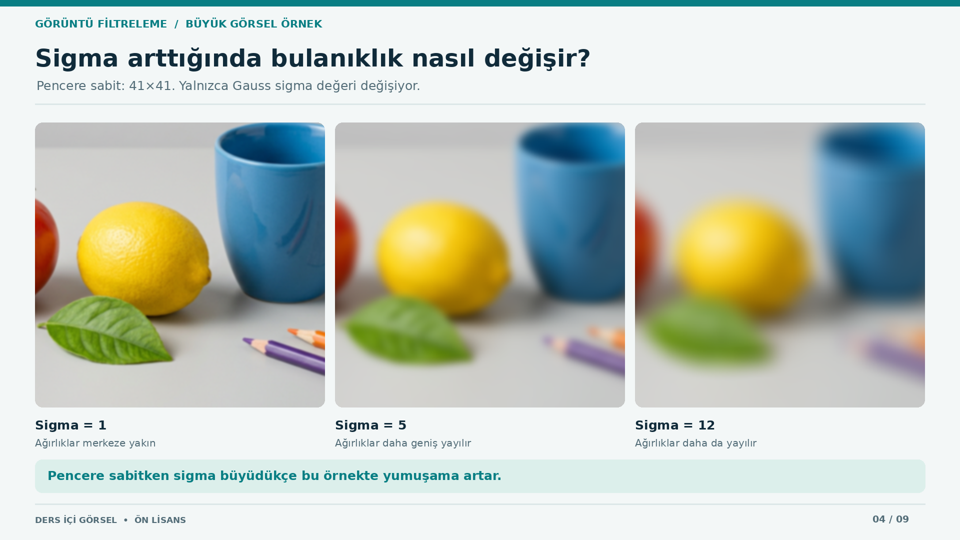

In [10]:
sunum_gorseli("04_sigma.png")

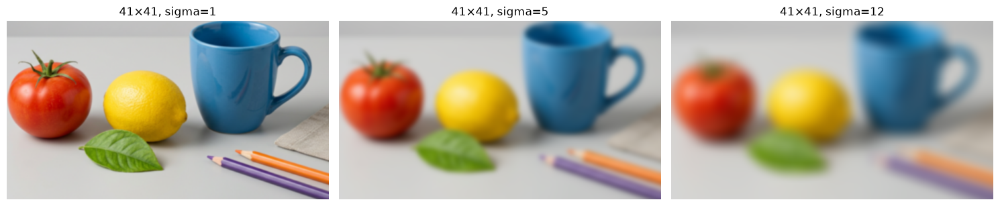

In [11]:
sigma_1 = cv2.GaussianBlur(resim, (41, 41), 1)
sigma_5 = cv2.GaussianBlur(resim, (41, 41), 5)
sigma_12 = cv2.GaussianBlur(resim, (41, 41), 12)
goster([yakin(sigma_1), yakin(sigma_5), yakin(sigma_12)],
       ["41×41, sigma=1", "41×41, sigma=5", "41×41, sigma=12"])

**Dene:** `sigma_5` satırındaki `5` değerini `3` yapın. Pencere aynıyken yumuşama nasıl değişti?

---
## 5. Tuz-biber gürültüsü ve medyan

**Kısa açıklama:** Tuz-biber gürültüsü, bazı piksellerin aniden beyaz veya siyah olmasıdır. Medyan filtre komşuluk değerlerini sıralar ve ortadaki değeri seçer; bu nedenle tek başına duran uç değerlerde genellikle etkilidir. Renkli görüntüde OpenCV her kanalı ayrı filtreler.

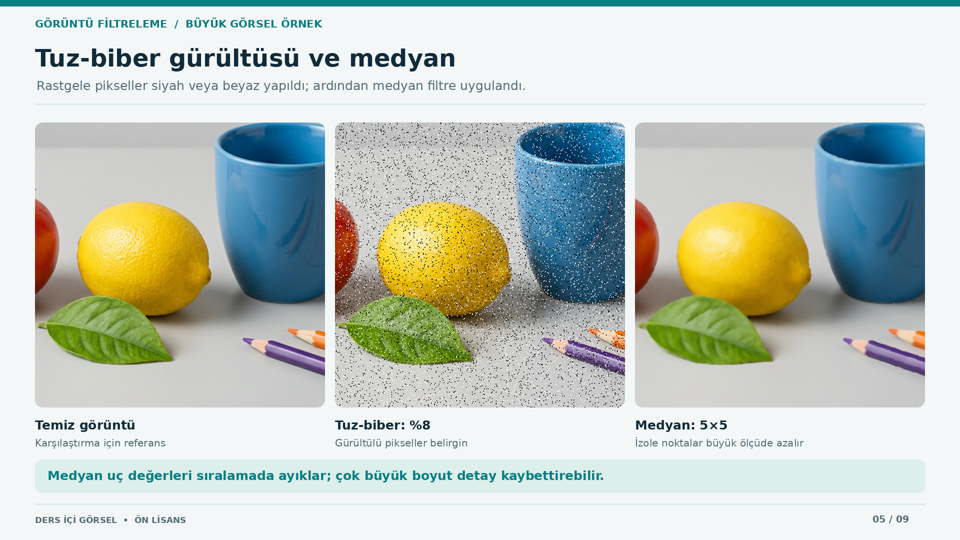

In [12]:
sunum_gorseli("05_tuz_biber_medyan.png")

Aşağıdaki yardımcı kod, seçilen piksel konumlarının yarısını beyaz, yarısını siyah yapar. Sabit **tohum**, aynı rastgele örneği yeniden elde etmemizi sağlar.

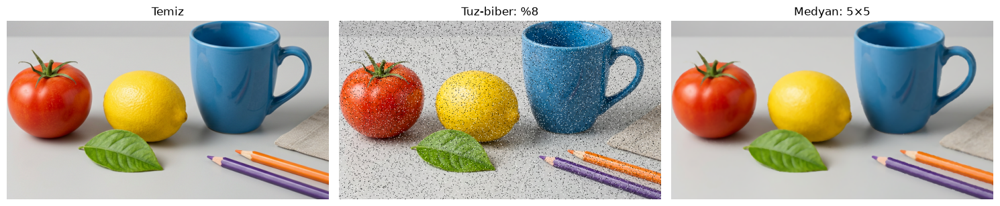

In [13]:
def tuz_biber_ekle(goruntu, oran=0.08, tohum=42):
    if not 0 <= oran <= 1:
        raise ValueError("Oran 0 ile 1 arasında olmalı.")
    rastgele = np.random.default_rng(tohum)
    sonuc = goruntu.copy()
    yukseklik, genislik = sonuc.shape[:2]
    adet = int(yukseklik * genislik * oran)
    konumlar = rastgele.choice(yukseklik * genislik, adet, replace=False)
    if sonuc.ndim == 3:
        pikseller = sonuc.reshape(-1, 3)
        pikseller[konumlar[:adet // 2]] = 255
        pikseller[konumlar[adet // 2:]] = 0
    else:
        sonuc.flat[konumlar[:adet // 2]] = 255
        sonuc.flat[konumlar[adet // 2:]] = 0
    return sonuc

gurultulu = tuz_biber_ekle(resim, oran=0.08, tohum=42)
tb_medyan = cv2.medianBlur(gurultulu, 5)
goster([yakin(resim), yakin(gurultulu), yakin(tb_medyan)],
       ["Temiz", "Tuz-biber: %8", "Medyan: 5×5"])

**Dene:** `oran=0.08` yerine `0.15` yazın. Ardından medyan boyutunu `5` yerine `3` veya `7` deneyin. Hangi durumda detay kaybı arttı? `medianBlur` boyutu 1'den büyük **tek sayı** olmalıdır. Değişiklikleri yaptığınız hücreyi ve onu kullanan sonraki hücreleri yeniden çalıştırın.

---
## 6. Gürültü türüne göre filtre seçelim

**Kısa açıklama:** Her görüntü ve gürültü için tek bir en iyi filtre yoktur. Sunumda iki farklı gürültü türünü karşılaştırdık: tuz-biber ve Gauss. Gauss gürültüsü, parlaklık değerlerine yayılmış rastgele değişimler ekler.

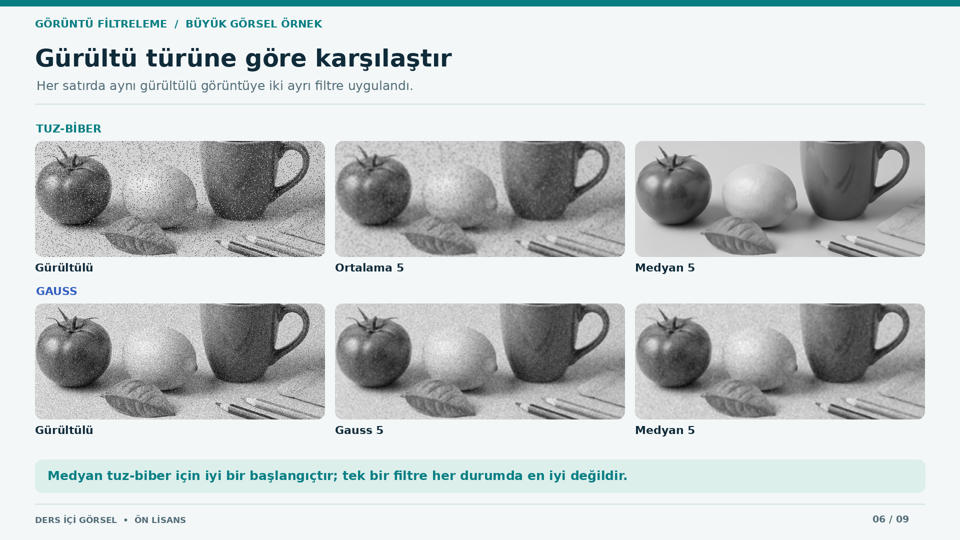

In [14]:
sunum_gorseli("06_filtre_secimi.png")

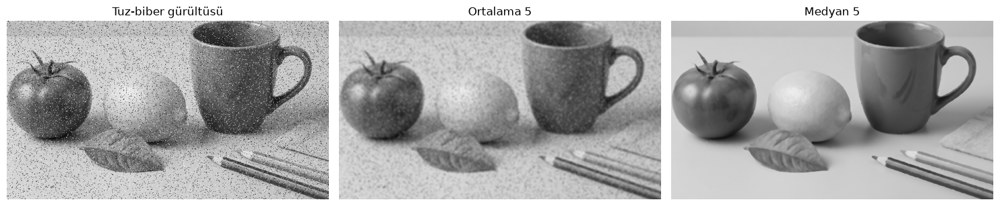

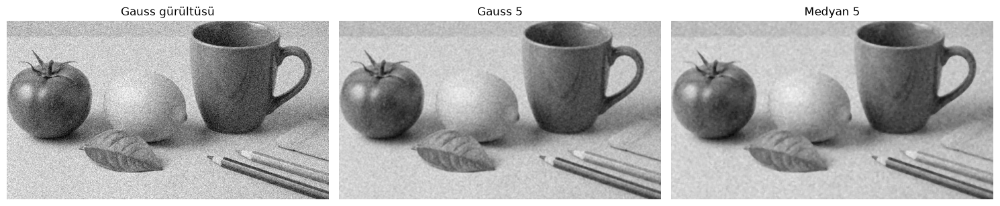

In [15]:
# 1. satır: %8 tuz-biber; ortalama 5 ve medyan 5.
gri_tuz_biber = tuz_biber_ekle(gri, oran=0.08, tohum=42)
tb_ortalama = cv2.blur(gri_tuz_biber, (5, 5))
tb_medyan_gri = cv2.medianBlur(gri_tuz_biber, 5)
goster([yakin(gri_tuz_biber), yakin(tb_ortalama), yakin(tb_medyan_gri)],
       ["Tuz-biber gürültüsü", "Ortalama 5", "Medyan 5"])

# 2. satır: sigma=25 Gauss gürültüsü; Gauss 5 ve medyan 5.
rng = np.random.default_rng(42)
gri_gauss_gurultulu = np.clip(gri.astype(np.float32) + rng.normal(0, 25, gri.shape), 0, 255).astype(np.uint8)
gauss_5 = cv2.GaussianBlur(gri_gauss_gurultulu, (5, 5), 0)
gauss_medyan_5 = cv2.medianBlur(gri_gauss_gurultulu, 5)
goster([yakin(gri_gauss_gurultulu), yakin(gauss_5), yakin(gauss_medyan_5)],
       ["Gauss gürültüsü", "Gauss 5", "Medyan 5"])

**Düşünelim:** Tuz-biberde siyah-beyaz noktaları hangi filtre daha iyi azalttı? Diğer satırda ince detaylara ne oldu? Gerçek görüntülerde sonuç gürültü miktarına ve parametrelere göre değişebilir.

---
## 7. Bilateral filtre: Kenarı gözeterek yumuşat

**Kısa açıklama:** Bilateral filtre yalnızca uzaklığı değil, piksellerin birbirine ne kadar benzediğini de kullanır. Bu nedenle bazı kenarları koruyarak yumuşatma sağlayabilir. `d` komşuluk çapını, `sigmaColor` parlaklık farkına duyarlılığı, `sigmaSpace` uzaklık etkisini belirler.

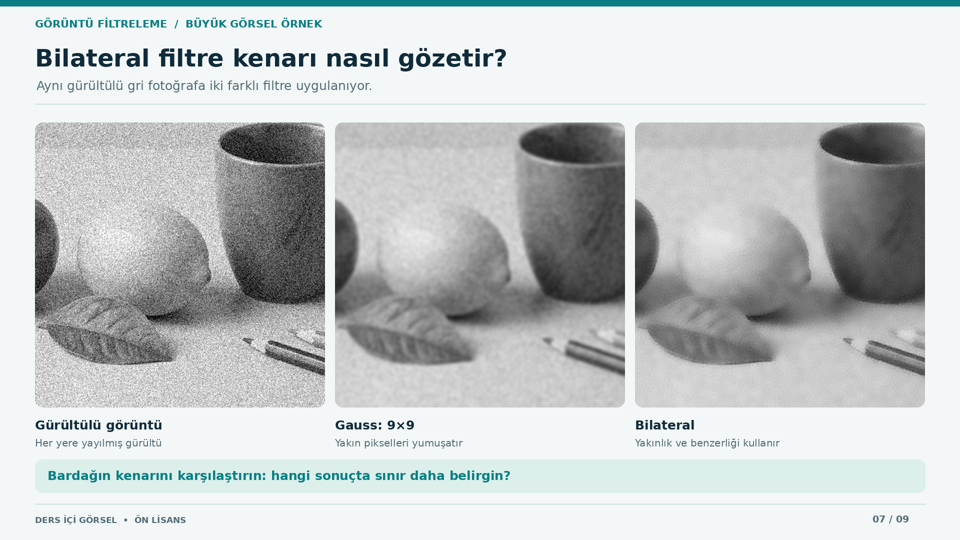

In [16]:
sunum_gorseli("07_bilateral.png")

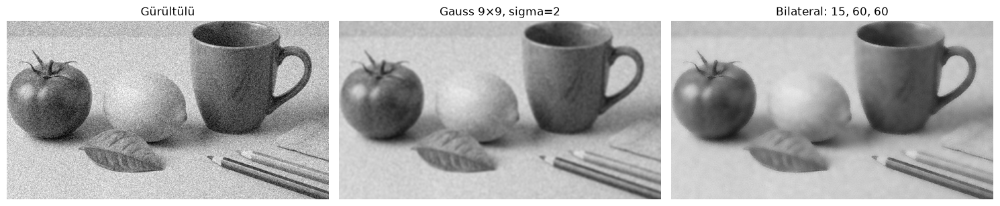

In [17]:
rng = np.random.default_rng(17)
bilateral_gurultulu = np.clip(gri.astype(np.float32) + rng.normal(0, 25, gri.shape), 0, 255).astype(np.uint8)
bilateral_gauss = cv2.GaussianBlur(bilateral_gurultulu, (9, 9), 2)
bilateral_sonuc = cv2.bilateralFilter(bilateral_gurultulu, 15, 60, 60)
goster([yakin(bilateral_gurultulu), yakin(bilateral_gauss), yakin(bilateral_sonuc)],
       ["Gürültülü", "Gauss 9×9, sigma=2", "Bilateral: 15, 60, 60"])

**Dene:** `bilateralFilter` içindeki ilk `60` değerini `30` yapın. Bardağın kenarını ve arka plandaki gürültüyü karşılaştırın.

### Ara uygulama: Kendi ortalama çekirdeğimizi yazalım

Sunumda gördüğünüz gibi 5×5 komşulukta 25 değer vardır. Her ağırlık `1/25` olduğunda ağırlıkların toplamı 1 olur. `filter2D`, bu çekirdeği görüntüye uygular.

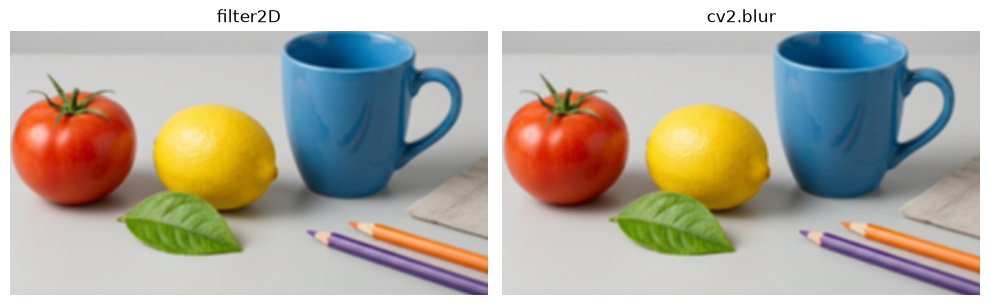

Çekirdek toplamı: 1.0
En büyük piksel farkı: 0


In [18]:
cekirdek = np.ones((5, 5), dtype=np.float32) / 25
kendi_ortalamam = cv2.filter2D(resim, -1, cekirdek)
hazir_ortalama = cv2.blur(resim, (5, 5))
goster([yakin(kendi_ortalamam), yakin(hazir_ortalama)], ["filter2D", "cv2.blur"])
fark = np.abs(kendi_ortalamam.astype(np.int16) - hazir_ortalama.astype(np.int16))
print("Çekirdek toplamı:", cekirdek.sum())
print("En büyük piksel farkı:", fark.max())

**Dene:** Çekirdeği 3×3 için `np.ones((3, 3), dtype=np.float32) / 9` yapın; `cv2.blur` boyutunu da `(3, 3)` seçin. Sonuçlar aynı veya yuvarlama nedeniyle çok yakın olmalıdır.

---
## 8. Keskinleştirme: Kenarları belirginleştir

**Kısa açıklama:** Keskinleştirme, piksel ile komşuları arasındaki farkı artırır. Kenarlar daha belirgin görünebilir; ancak gürültü ve yapay kenar izleri de büyüyebilir. Sunumdaki **α = 1** ve **α = 3** örneklerini deneyelim.

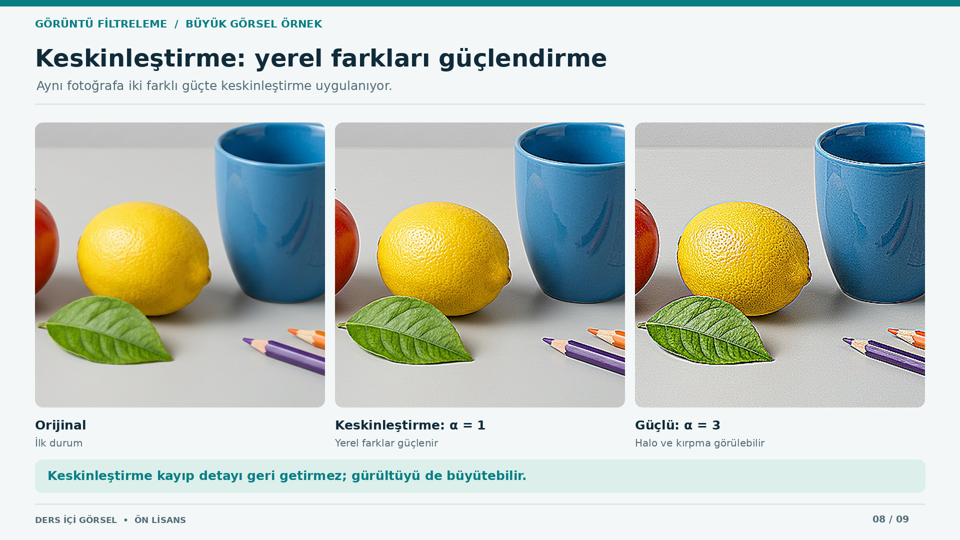

In [19]:
sunum_gorseli("08_keskinlestirme.png")

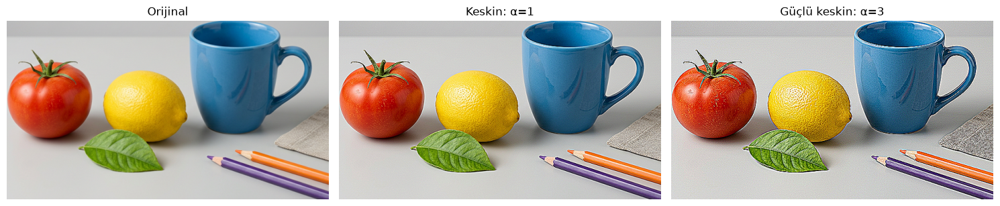

α=1 çekirdeği:
 [[ 0. -1.  0.]
 [-1.  5. -1.]
 [ 0. -1.  0.]]
Çekirdek toplamı: 1.0


In [20]:
def keskin_cekirdegi(alfa):
    return np.array([[0, -alfa, 0],
                     [-alfa, 1 + 4 * alfa, -alfa],
                     [0, -alfa, 0]], dtype=np.float32)

keskin_1 = cv2.filter2D(resim, -1, keskin_cekirdegi(1))
keskin_3 = cv2.filter2D(resim, -1, keskin_cekirdegi(3))
goster([yakin(resim), yakin(keskin_1), yakin(keskin_3)],
       ["Orijinal", "Keskin: α=1", "Güçlü keskin: α=3"])
print("α=1 çekirdeği:\n", keskin_cekirdegi(1))
print("Çekirdek toplamı:", keskin_cekirdegi(1).sum())

**Dene:** `keskin_cekirdegi(3)` yerine `keskin_cekirdegi(0.3)` kullanın. Daha hafif keskinleştirmeyle nasıl bir fark görüyorsunuz? Keskinleştirme kayıp detayları gerçekten geri getirmez; `uint8` çıktıda değerler 0–255 aralığına kırpılır.

---
## 9. Plaka örneği: İşlemleri sırayla uygula

**Kısa açıklama:** Sunumdaki akışta önce gürültü azaltılır, sonra kontrast gerilir ve son olarak hafif keskinleştirme yapılır. Görsel yapaydır; burada OCR veya gerçek plaka tanıma yapılmaz.

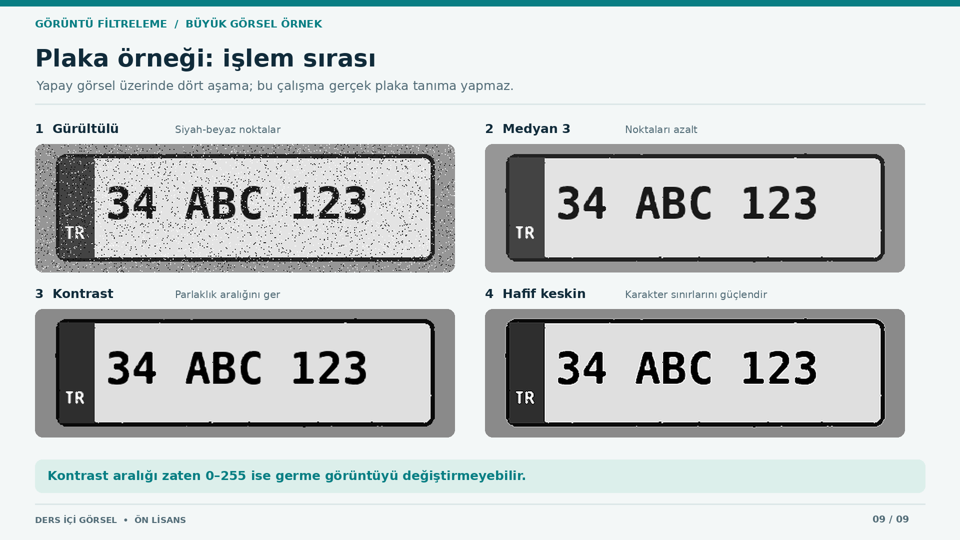

In [21]:
sunum_gorseli("09_plaka.png")

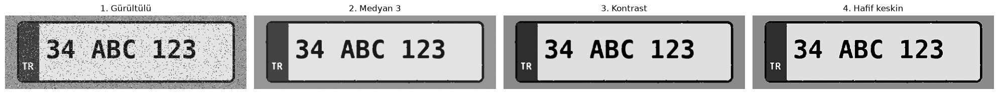

Medyan sonrası en küçük ve en büyük değer: 25 255


In [22]:
plaka = cv2.imread(str(DOSYALAR / "plaka.png"), cv2.IMREAD_GRAYSCALE)
if plaka is None:
    raise FileNotFoundError("Plaka görseli okunamadı.")
plaka_gurultulu = tuz_biber_ekle(plaka, oran=0.06, tohum=8)
plaka_medyan = cv2.medianBlur(plaka_gurultulu, 3)

# En küçük ve en büyük değerleri 0–255 aralığına yayalım.
alt, ust = int(plaka_medyan.min()), int(plaka_medyan.max())
if alt == ust:  # Sabit görüntüde sıfıra bölmeyelim.
    plaka_kontrast = plaka_medyan.copy()
else:
    plaka_kontrast = np.clip((plaka_medyan.astype(np.float32) - alt) * 255 / (ust - alt), 0, 255).astype(np.uint8)
plaka_son = cv2.filter2D(plaka_kontrast, -1, keskin_cekirdegi(0.3))

# Sunumdaki plaka bölgesi.
def plaka_yakin(goruntu):
    return goruntu[72:225, 70:570]
goster([plaka_yakin(plaka_gurultulu), plaka_yakin(plaka_medyan), plaka_yakin(plaka_kontrast), plaka_yakin(plaka_son)],
       ["1. Gürültülü", "2. Medyan 3", "3. Kontrast", "4. Hafif keskin"])
print("Medyan sonrası en küçük ve en büyük değer:", alt, ust)

**Dene:** Medyan boyutunu `3` yerine `5` yapın. Karakterlerin kenarlarında veya ince parçalarında kayıp var mı? Minimum ve maksimum değerler zaten 0 ve 255 ise kontrast germe görüntüyü değiştirmeyebilir. Gerçek bir OCR sisteminin başarısı ayrıca ölçülmelidir.

---
## 10. Sonucu kaydedelim

`cv2.imwrite` görüntüyü dosyaya yazar. Aynı isimde dosya varsa üzerine yazılır. OpenCV'nin BGR görüntüsü doğrudan kaydedilebilir.

In [23]:
hedef = CIKTILAR / "medyan_sonuc.png"
basarili = cv2.imwrite(str(hedef), tb_medyan)
print("Kaydedildi:" if basarili else "Kaydedilemedi:", hedef)

Kaydedildi: ciktilar/medyan_sonuc.png


## 11. Kendin dene

Çalışan örnekte önce tahmin edin, sonra parametreleri değiştirin:

1. `filtre` değerini `"ortalama"`, `"gauss"` ve `"medyan"` yapın. Noktaları ve detayları karşılaştırın.
2. `boyut` değerini 3, 5 ve 11 deneyin. Hangisinde daha fazla detay kayboldu?
3. Bölüm 5'te gürültü oranını artırın, o hücreyi ve bu hücreyi yeniden çalıştırın.

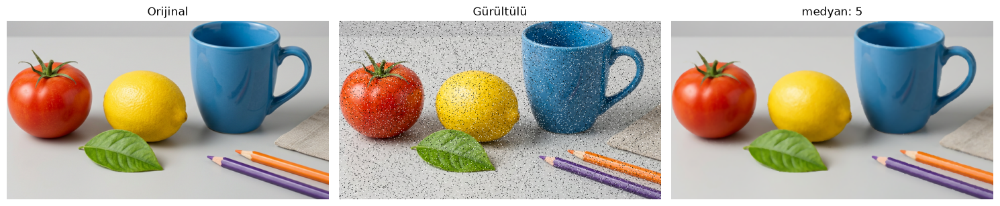

In [24]:
filtre = "medyan"  # "ortalama", "gauss" veya "medyan"
boyut = 5          # bu deneyde: 3, 5, 7, 11, ...
if boyut <= 1 or boyut % 2 == 0:
    raise ValueError("Boyut 1'den büyük tek sayı olmalı.")
if filtre == "ortalama":
    deneme = cv2.blur(gurultulu, (boyut, boyut))
elif filtre == "gauss":
    deneme = cv2.GaussianBlur(gurultulu, (boyut, boyut), 0)
elif filtre == "medyan":
    deneme = cv2.medianBlur(gurultulu, boyut)
else:
    raise ValueError("Filtre: ortalama, gauss veya medyan olmalı.")
goster([yakin(resim), yakin(gurultulu), yakin(deneme)], ["Orijinal", "Gürültülü", f"{filtre}: {boyut}"])

## 12. Kısa tekrar

1. 3×3 ortalama filtre, komşuları nasıl kullanır?
2. Görüntü sınırlarında neden dolgu gerekir?
3. Tuz-biber gürültüsünde neden çoğunlukla medyan denenir?
4. Büyük bir çekirdeğin ve aşırı keskinleştirmenin olası bedeli nedir?

<details><summary>Örnek cevapları aç</summary>

1. Dokuz değeri eşit ağırlıkla toplar; toplamı dokuza böler.
2. Kenardaki bir pikselin bazı komşuları görüntünün dışında kalır.
3. Ortancayı seçtiği için tek başına duran uç değerlerden genellikle daha az etkilenir.
4. Büyük çekirdek ince ayrıntıları silebilir; aşırı keskinleştirme gürültüyü ve yapay izleri büyütebilir.
</details>

### Sorun giderme
- **Dosya bulunamadı:** ZIP'in tamamını çıkarın. Defterin yanında `dosyalar` klasörü olmalı; ilk hücrede yazan çalışma dizinini kontrol edin.
- **Paket bulunamadı:** `requirements.txt` dosyasındaki paketleri defterin Python ortamına kurup çekirdeği yeniden başlatın.
- **OpenCV boyut hatası:** Bu örneklerde Gauss için pozitif tek boyut, medyan için 1'den büyük tek boyut kullanın. `cv2.blur` çift boyuta da izin verir.
- **Görüntüler farklı görünüyor:** Hücreleri sırayla çalıştırın. Sunumdaki örnekler yakınlaştırılıp kırpılmıştır; işlem parametreleri bu defterle eşleştirilmiştir.

**Kaynaklar:** [OpenCV — Smoothing Images](https://docs.opencv.org/4.x/d4/d13/tutorial_py_filtering.html) · [OpenCV — Image Filtering](https://docs.opencv.org/4.x/d4/d86/group__imgproc__filter.html). Renkli örnek bu ders için yapay zekâ ile; plaka görseli programatik olarak üretilmiştir.